
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/10_Lab_langevineP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Movimiento browniano

Una partícula inmersa en un líquido experimenta fricción y
fluctuaciones producidas por las colisiones moleculares.
Para una partícula libre, la ecuación de Langevin es

$$
m\frac{d^2x}{dt^2}
=
-\gamma\frac{dx}{dt}+\xi(t),
$$

donde $m$ es la masa, $\gamma$ es el coeficiente de fricción
y $\xi(t)$ es la fuerza fluctuante.

## Propiedades del ruido térmico

La fuerza fluctuante tiene media cero:

$$
\langle\xi(t)\rangle=0.
$$

Esto significa que las fluctuaciones no tienen una dirección
preferida en promedio.

Para un líquido en equilibrio térmico, la correlación es

$$
\langle\xi(t)\xi(t')\rangle
=
2\gamma k_BT\,\delta(t-t').
$$

La delta de Dirac es una distribución matemática, definida
por su acción dentro de una integral:

$$
\int_{-\infty}^{\infty}
\delta(t-t')f(t')\,dt'=f(t).
$$

La correlación del ruido blanco se concentra en tiempos
coincidentes y se anula para tiempos distintos. El ruido
blanco se interpreta mediante sus integrales temporales.

## Formulación mediante un proceso de Wiener

Definimos la velocidad:

$$
v=\frac{dx}{dt}.
$$

El sistema se escribe formalmente como

$$
\begin{aligned}
\frac{dx}{dt}&=v,\\
m\frac{dv}{dt}&=-\gamma v+\xi(t).
\end{aligned}
$$

Mediante un proceso de Wiener, su formulación precisa es

$$
\begin{aligned}
dx_t&=v_t\,dt,\\
m\,dv_t&=-\gamma v_t\,dt
+\sqrt{2\gamma k_BT}\,dW_t.
\end{aligned}
$$

Los incrementos de Wiener en intervalos disjuntos son
independientes y satisfacen

$$
\Delta W_n
=
W_{t_{n+1}}-W_{t_n}
\sim\mathcal{N}(0,\Delta t).
$$

Para generarlos numéricamente usamos

$$
\Delta W_n=\sqrt{\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1),
$$

con un nuevo $Z_n$ independiente en cada paso.

## Régimen sobreamortiguado

En escalas temporales grandes frente a $m/\gamma$, podemos
despreciar la inercia:

$$
\gamma\frac{dx}{dt}=\xi(t).
$$

La ecuación estocástica se reduce a

$$
dx_t=\sqrt{2D}\,dW_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Para una posición inicial fija $x_0$, la solución es

$$
x_t=x_0+\sqrt{2D}\,W_t,
\qquad W_0=0.
$$

La media permanece en la posición inicial y la varianza
aumenta linealmente:

$$
\mathbb{E}[x_t]=x_0,
\qquad
\operatorname{Var}(x_t)=2Dt.
$$

Entre dos tiempos, la actualización exacta de este modelo es

$$
x_{n+1}
=
x_n+\sqrt{2D\,\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1).
$$

Esta expresión describe una partícula libre en el régimen
sobreamortiguado.

Al incorporar un resorte, añadimos una deriva restauradora:

$$
dx_t
=
-\frac{k}{\gamma}x_t\,dt
+
\sqrt{2D}\,dW_t.
$$

Su aproximación de Euler–Maruyama es

$$
x_{n+1}
=
x_n-\frac{k}{\gamma}x_n\Delta t
+\sqrt{2D\,\Delta t}\,Z_n.
$$

El resorte confina las posiciones y el ruido mantiene las
fluctuaciones. A tiempos largos, la distribución se aproxima
a una gaussiana con media cero y varianza $k_BT/k$.

# Movimiento Browniano

\begin{equation}
\frac{d^2x}{dt^2}=-\gamma \frac{dx}{dt} + \xi(t)
\end{equation}

$\eta(t)$ Fuerza aleatoria producida por las colisiones colisiones moleculares $\langle \eta(t)\rangle=0.$, en promedio las colisiones que se presentan dan cero.
Para un liquido en equilibrio térmico, la intensidad viene dada por:

$\langle\xi(t)\xi(t') \rangle = 2\gamma k_B T  \delta(t-t') $

Para $\delta(\Delta t) = 0$, si $t!=t'$,

Para $\delta(\Delta t) = \infty$, si $t = t'$,



\begin{equation}
\frac{dx}{dt}=v
\end{equation}


\begin{equation}
\frac{dv}{dt}=-\gamma  \frac{dx}{dt} + \xi(t)
\end{equation}

El sistema de ecuaciones, se transforma, en, empleando un proceo de Wigner:


\begin{equation}
\begin{aligned}
dx(t)&=v(t)\,dt,\\
m\,dv(t)&=-\gamma v(t)\,dt
+\sqrt{2\gamma k_BT}\,dW(t).
\end{aligned}
\end{equation}



Cuya solución es

\begin{equation}
x(t+\Delta t)
=
x(t)+\sqrt{2D\,\Delta t}\,Z,
\qquad Z\sim\mathcal N(0,1).
\end{equation}



 # Simulacion del movimiento browniano

 Realizar un codigo para simular el movimiento browniano sin fuerza externa y con fuerza externa de la forma f=-kx

## 1. Simulación del movimiento browniano sin fuerza externa

Simularemos varias trayectorias independientes de una partícula browniana sometida únicamente a agitación térmica (sin potencial externo). La partícula debería alejarse del origen a medida que pasa el tiempo (difusión libre).

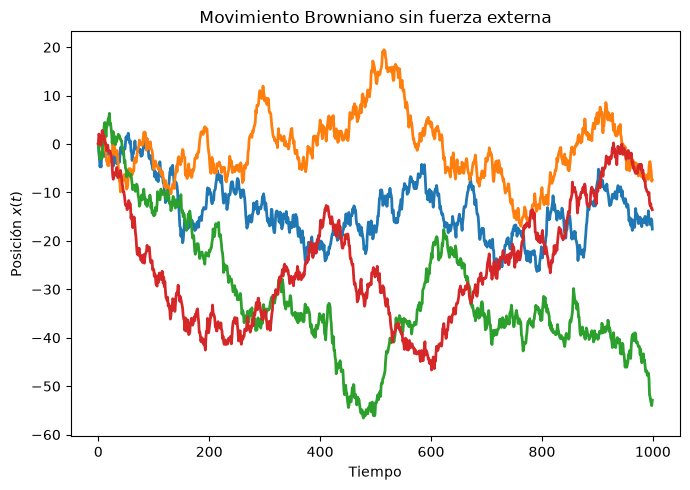

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros de la simulación
N_pasos = 1000
N_trayectorias = 4
dt = 1.0
D = 0.5  # Coeficiente de difusión
escala_ruido = np.sqrt(2 * D * dt)

plt.figure(figsize=(7, 5))

# Simulamos las trayectorias
for i in range(N_trayectorias):
    # Generamos los pasos aleatorios (ruido blanco gaussiano)
    Z = np.random.randn(N_pasos)
    dx = escala_ruido * Z
    
    # Condición inicial x(0) = 0
    x = np.zeros(N_pasos)
    x[0] = 0
    
    # Ecuación de movimiento: x(t + dt) = x(t) + dx
    for t in range(1, N_pasos):
        x[t] = x[t-1] + dx[t]
        
    plt.plot(x, linewidth=2)

plt.xlabel('Tiempo')
plt.ylabel('Posición $x(t)$')
plt.title('Movimiento Browniano sin fuerza externa')
plt.grid(False)
plt.tight_layout()
plt.show()

## 2. Simulación con fuerza externa: Potencial armónico (\(f = -kx\))

Ahora aplicamos una fuerza externa de la forma \(F = -kx\), que actúa como un resorte que "tira" de la partícula hacia el centro del potencial ($x=0$). En este caso, la ecuación de movimiento discreta (en el régimen sobreamortiguado) se modifica a:
$$
 x(t+\Delta t) = x(t) - \frac{k}{\gamma}x(t)\,\Delta t + \sqrt{2D\,\Delta t}\,Z
$$
Las partículas ya no se difundirán indefinidamente, sino que quedarán confinadas fluctuando alrededor del centro (proceso de Ornstein-Uhlenbeck).

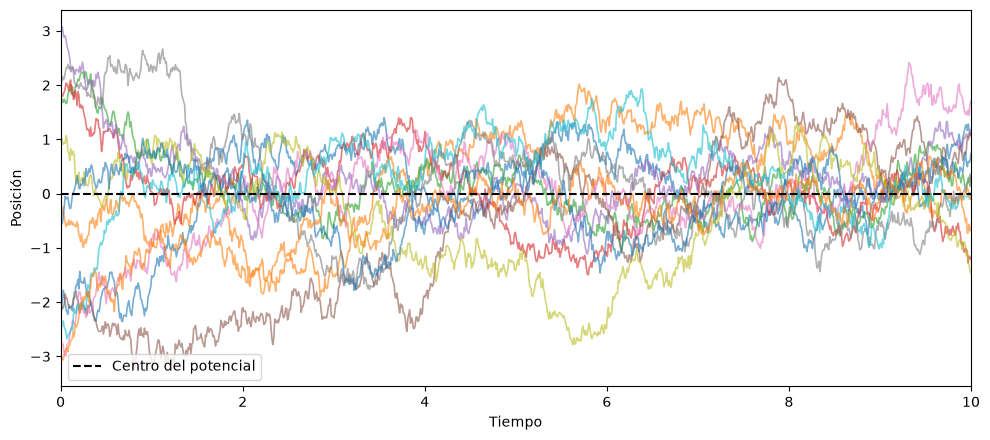

In [3]:
# Parámetros del potencial armónico
N_pasos = 1000
dt = 0.01
k = 1.0      # Constante del resorte
gamma = 1.0  # Coeficiente de fricción
D = 0.5      # Coeficiente de difusión
escala_ruido = np.sqrt(2 * D * dt)

N_trayectorias = 12
tiempo = np.linspace(0, N_pasos * dt, N_pasos)

plt.figure(figsize=(10, 4.5))

# Simulamos múltiples trayectorias
for i in range(N_trayectorias):
    Z = np.random.randn(N_pasos)
    dx = escala_ruido * Z
    
    x = np.zeros(N_pasos)
    x[0] = np.random.uniform(-3.5, 3.5)  # Inicio aleatorio
    
    for t in range(1, N_pasos):
        # Ecuación de movimiento con fuerza externa
        x[t] = x[t-1] - (k / gamma) * x[t-1] * dt + dx[t]
        
    # alpha=0.6 hace que las líneas se vean más suaves/transparentes
    plt.plot(tiempo, x, linewidth=1.2, alpha=0.6)

# Línea del centro del potencial
plt.axhline(0, color='black', linestyle='--', label='Centro del potencial')

plt.xlabel('Tiempo')
plt.ylabel('Posición')
plt.xlim(0, 10)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

### Interpretación física

*   **Sin fuerza (Difusión libre):** La varianza del desplazamiento crece linealmente con el tiempo \(\langle x^2 \rangle \propto t\). Las partículas se alejan indefinidamente de su origen.
*   **Con fuerza (\(F = -kx\)):** La fuerza restauradora limita el crecimiento de la varianza. Tras un tiempo característico, la partícula alcanza un estado estacionario. Por el teorema de equipartición de la energía, la distribución de posiciones converge a una distribución gaussiana centrada en 0 con varianza \(\langle x^2 \rangle = \frac{k_B T}{k} = \frac{D \gamma}{k}\).

# Con modelos tipo Score

# Dinámica de Langevin con un campo score

Para una densidad de probabilidad $p_\theta(\mathbf{x})$,
definimos el campo score como

$$
\mathbf{s}_\theta(\mathbf{x})
=
\nabla_{\mathbf{x}}\log p_\theta(\mathbf{x}).
$$

Este campo apunta hacia la dirección de máximo crecimiento
local del logaritmo de la densidad.

## Relación entre el score y la fuerza

Para una distribución de Boltzmann,

$$
p_\theta(\mathbf{x})
=
\frac{1}{Z_\theta}
\exp\left[-\frac{U_\theta(\mathbf{x})}{k_BT}\right],
$$

el score es

$$
\mathbf{s}_\theta(\mathbf{x})
=
-\frac{1}{k_BT}\nabla_{\mathbf{x}}U_\theta(\mathbf{x}).
$$

Como la fuerza es $\mathbf{F}_\theta=-\nabla U_\theta$,

$$
\mathbf{F}_\theta(\mathbf{x})
=
k_BT\,\mathbf{s}_\theta(\mathbf{x}).
$$

## Ecuación estocástica

La dinámica sobreamortiguada es

$$
d\mathbf{X}_t
=
\frac{\mathbf{F}_\theta(\mathbf{X}_t)}{\gamma}\,dt
+
\sqrt{2D}\,d\mathbf{W}_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Sustituyendo la fuerza por su expresión en términos del score:

$$
d\mathbf{X}_t
=
D\,\mathbf{s}_\theta(\mathbf{X}_t)\,dt
+
\sqrt{2D}\,d\mathbf{W}_t.
$$

El campo produce un desplazamiento dirigido y el ruido
mantiene las fluctuaciones. Durante esta evolución,
$\theta$ permanece fijo.

## Incrementos de Wiener

En $d$ dimensiones,

$$
\Delta\mathbf{W}_n
=
\sqrt{\Delta t}\,\boldsymbol{\epsilon}_n,
\qquad
\boldsymbol{\epsilon}_n\sim\mathcal{N}(\mathbf{0},I_d),
$$

con nuevos vectores independientes en cada paso.

## Actualización numérica

La aproximación de Euler–Maruyama es

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
D\,\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2D\Delta t}\,\boldsymbol{\epsilon}_n.
$$

En unidades donde $D=1$:

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2\Delta t}\,\boldsymbol{\epsilon}_n.
$$

Con el score exacto y condiciones adecuadas de convergencia,
la dinámica continua reproduce $p_\theta$ a tiempos largos.
La actualización numérica introduce un error de discretización.

## Ejemplo: distribución gaussiana

Para una gaussiana con media $\boldsymbol{\mu}$ y
covarianza $vI_d$,

$$
\mathbf{s}(\mathbf{x})
=
-\frac{\mathbf{x}-\boldsymbol{\mu}}{v}.
$$



In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Gaussiana objetivo
mu = 0.0
varianza = 1.0

def densidad(x):
    return np.exp(-(x - mu)**2 / (2 * varianza)) / np.sqrt(
        2 * np.pi * varianza
    )

def score(x):
    return -(x - mu) / varianza



In [5]:
rng = np.random.default_rng(42)

n_trayectorias = 200
n_pasos = 1_000
dt = 0.01

# Todas las trayectorias comienzan en la misma posición
x = np.zeros((n_trayectorias, n_pasos))
np.shape(x)
t = np.arange(n_pasos+1 ) * dt

In [6]:
x = np.zeros((n_trayectorias, n_pasos + 1))

# Todas las trayectorias comienzan en cero
x[:, 0] = 0.0

for k in range(n_trayectorias):
    for j in range(n_pasos):
        ruido = rng.normal()

        x[k, j + 1] = (
            x[k, j]
            + dt * score(x[k, j])
            + np.sqrt(2 * dt) * ruido
        )

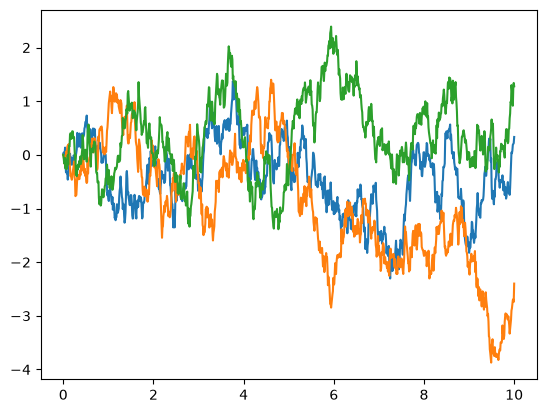

In [7]:
plt.plot(t, x[0])
plt.plot(t, x[1])
plt.plot(t, x[2])

In [8]:
x=np.concat(x)

Media de las muestras:    -0.0092
Varianza de las muestras: 0.9434
Varianza teórica discreta: 1.0050


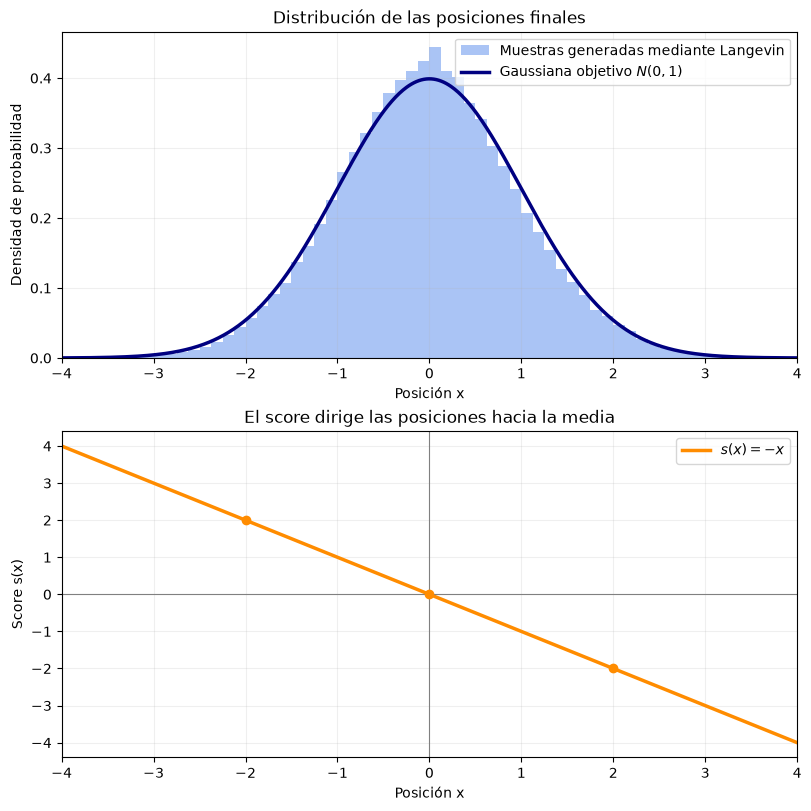

In [9]:
# Resultados
print(f"Media de las muestras:    {np.mean(x):.4f}")
print(f"Varianza de las muestras: {np.var(x):.4f}")

# Varianza estacionaria de la actualización discreta
varianza_discreta = varianza / (1 - dt / (2 * varianza))
print(f"Varianza teórica discreta: {varianza_discreta:.4f}")


# Gráficas
eje = np.linspace(-4, 4, 600)

fig, axes = plt.subplots(
    2, 1, figsize=(8, 8), constrained_layout=True
)

# Densidad objetivo e histograma de posiciones finales
axes[0].hist(
    x,
    bins=np.linspace(-4, 4, 65),
    density=True,
    color="cornflowerblue",
    alpha=0.55,
    label="Muestras generadas mediante Langevin"
)

axes[0].plot(
    eje,
    densidad(eje),
    color="navy",
    linewidth=2.5,
    label=r"Gaussiana objetivo ${N}(0,1)$"
)

axes[0].set(
    title="Distribución de las posiciones finales",
    xlabel="Posición x",
    ylabel="Densidad de probabilidad",
    xlim=(-4, 4)
)
axes[0].legend()
axes[0].grid(alpha=0.2)

# Campo score
axes[1].plot(
    eje,
    score(eje),
    color="darkorange",
    linewidth=2.5,
    label=r"$s(x) = -x$"
)

axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].axvline(mu, color="gray", linewidth=0.8)

axes[1].scatter(
    [-2, 0, 2],
    score(np.array([-2, 0, 2])),
    color="darkorange",
    zorder=3
)

axes[1].set(
    title="El score dirige las posiciones hacia la media",
    xlabel="Posición x",
    ylabel="Score s(x)",
    xlim=(-4, 4)
)
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.show()

Simule la dinámica de Langevin de partículas inicialmente distribuidas al azar en el plano, utilizando el campo score de una gaussiana de media \((0,0)\) y covarianza identidad. Visualice el campo y cinco trayectorias. Compare la distribución final de las partículas con la gaussiana objetivo y calcule su media y covarianza.

## Simulación bidimensional

Simularemos partículas en el plano que inicialmente están distribuidas al azar. Utilizaremos el campo score de una gaussiana estándar bivariada (media en el origen, matriz de covarianza identidad). A medida que avanza el tiempo, la combinación de la fuerza dirigida (score) y el ruido estocástico debería hacer que la distribución empírica de las partículas converja a la distribución objetivo \(N(0, I)\).

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

# 1. Definir parámetros y score
mu_2d = np.array([0.0, 0.0])
cov_2d = np.eye(2)
inv_cov = np.linalg.inv(cov_2d)

# Score para una gaussiana multivariada: s(x) = -inv_cov * (x - mu)
def score_2d(x):
    return -np.dot(x - mu_2d, inv_cov)

rng = np.random.default_rng(42)
D = 1.0
dt = 0.01
n_pasos = 1000

# --- A. Simulación de 5 trayectorias para visualización ---
n_trayectorias_vis = 5
inicio_traj = rng.uniform(-3.5, 3.5, size=(n_trayectorias_vis, 2))
trayectorias = np.zeros((n_trayectorias_vis, n_pasos + 1, 2))
trayectorias[:, 0, :] = inicio_traj

for t in range(n_pasos):
    ruido = rng.normal(size=(n_trayectorias_vis, 2))
    trayectorias[:, t+1, :] = (
        trayectorias[:, t, :]
        + dt * score_2d(trayectorias[:, t, :])
        + np.sqrt(2 * D * dt) * ruido
    )

# --- B. Simulación de un ensamble grande para estadísticas y densidad ---
n_particulas = 10000
x_ensamble = rng.uniform(-3, 3, size=(n_particulas, 2))

for t in range(n_pasos):
    ruido = rng.normal(size=(n_particulas, 2))
    x_ensamble = (
        x_ensamble
        + dt * score_2d(x_ensamble)
        + np.sqrt(2 * D * dt) * ruido
    )

# Estadísticas finales
media_final = np.mean(x_ensamble, axis=0)
cov_final = np.cov(x_ensamble.T)

print(f"Media final: {media_final}")
print(f"Covarianza final:\n{cov_final}")

Media final: [ 0.00917278 -0.00540124]
Covarianza final:
[[1.00970785 0.00424547]
 [0.00424547 1.01727912]]


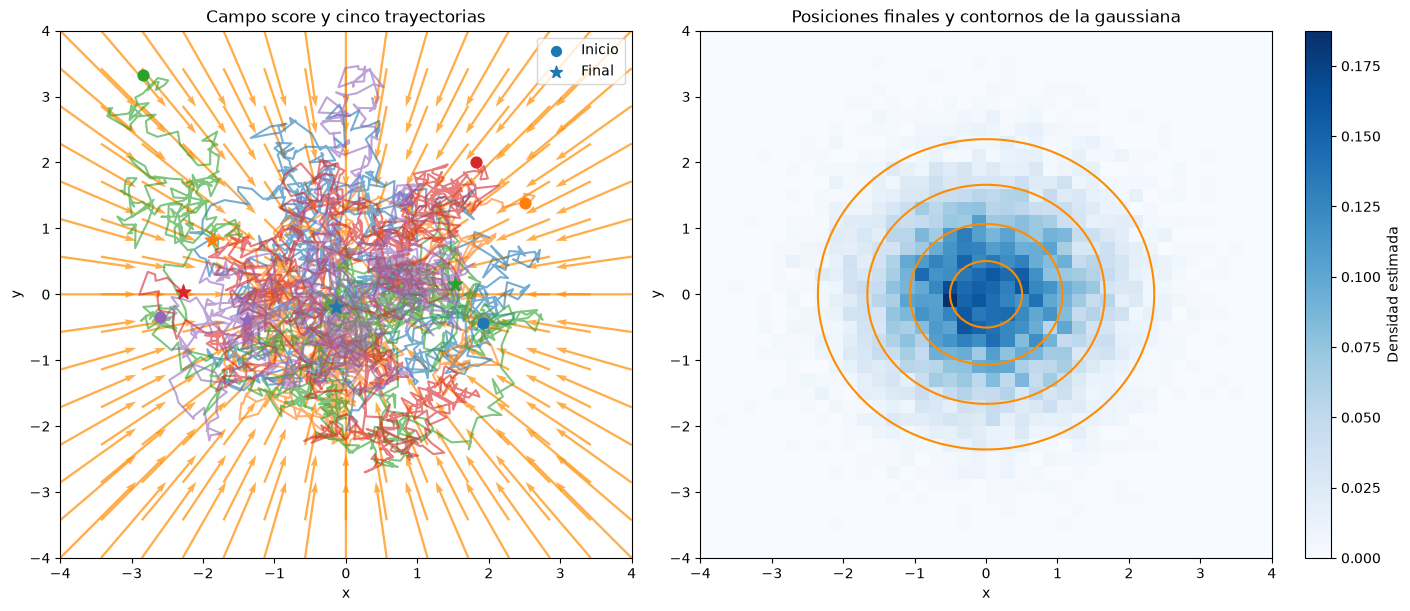

In [11]:
# --- Visualización ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

# --- Panel Izquierdo: Campo vectorial y trayectorias ---
X, Y = np.meshgrid(np.linspace(-4, 4, 15), np.linspace(-4, 4, 15))
pos = np.dstack((X, Y))
S = score_2d(pos)

axes[0].quiver(X, Y, S[:, :, 0], S[:, :, 1], color='darkorange', alpha=0.7, scale=30)
colores = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

for i in range(n_trayectorias_vis):
    axes[0].plot(trayectorias[i, :, 0], trayectorias[i, :, 1], color=colores[i], alpha=0.6, linewidth=1.5)
    axes[0].scatter(trayectorias[i, 0, 0], trayectorias[i, 0, 1], color=colores[i], marker='o', s=60, zorder=3)
    axes[0].scatter(trayectorias[i, -1, 0], trayectorias[i, -1, 1], color=colores[i], marker='*', s=120, zorder=3)

# Añadir elementos dummy para la leyenda
axes[0].scatter([], [], color='tab:blue', marker='o', s=50, label='Inicio')
axes[0].scatter([], [], color='tab:blue', marker='*', s=80, label='Final')

axes[0].set_title("Campo score y cinco trayectorias")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_xlim(-4, 4)
axes[0].set_ylim(-4, 4)
axes[0].legend(loc='upper right')

# --- Panel Derecho: Histograma 2D y contornos gaussianos ---
h = axes[1].hist2d(x_ensamble[:, 0], x_ensamble[:, 1], bins=40, range=[[-4, 4], [-4, 4]], cmap='Blues', density=True)

x_grid = np.linspace(-4, 4, 100)
y_grid = np.linspace(-4, 4, 100)
X_grid, Y_grid = np.meshgrid(x_grid, y_grid)
pos_grid = np.dstack((X_grid, Y_grid))

rv = multivariate_normal(mu_2d, cov_2d)
Z = rv.pdf(pos_grid)
axes[1].contour(X_grid, Y_grid, Z, levels=[0.01, 0.04, 0.09, 0.14], colors='darkorange')

axes[1].set_title("Posiciones finales y contornos de la gaussiana")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_xlim(-4, 4)
axes[1].set_ylim(-4, 4)

fig.colorbar(h[3], ax=axes[1], label='Densidad estimada')

plt.show()

### Resultados y conclusiones

Al finalizar la simulación y comparar el ensamble con la distribución teórica, se observa que:

*   **La fuerza dirigida (Score):** El campo $(\mathbf{s}(\mathbf{x}) = -\mathbf{x})$ actúa como una fuerza restauradora que atrae a todas las partículas hacia el origen $((0,0))$.
*   **El papel del ruido:** Sin el término de ruido $(\sqrt{2\Delta t}\,\boldsymbol{\epsilon}_n)$, todas las partículas colapsarían al origen (como un mínimo de potencial). El ruido inyecta energía térmica, evitando el colapso y manteniendo la varianza.
*   **Equilibrio:** Cuando el efecto restaurador del score y la dispersión del ruido se equilibran, la distribución de partículas alcanza el estado estacionario.

La media final (cercana a `[0, 0]`) y la matriz de covarianza final (con valores diagonales cercanos a `1.0` y fuera de la diagonal cercanos a `0`) confirman numéricamente que **el muestreo mediante dinámica de Langevin converge correctamente a la distribución gaussiana estándar objetivo**.